# 🏈 NFL Data Analysis — Part 3: Team Comparison

Time to answer the big question: **which teams are better and why?** We'll compare offenses, defenses, and quarterback performances using data-driven metrics that explain what actually makes a team win.

---
## What you'll learn
- How to rank teams offensively and defensively
- Why yards gained per play is a key efficiency metric
- Which QBs performed best and why
- How defensive pressure (sacks, hurries) disrupts offenses
- A team "report card" to compare two teams head-to-head

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (13, 6)
plt.rcParams['font.size'] = 12
sns.set_theme(style='whitegrid', palette='deep')

games   = pd.read_csv('../data/games.csv')
plays   = pd.read_csv('../data/plays.csv')
players = pd.read_csv('../data/players.csv')
pff     = pd.read_csv('../data/pffScoutingData.csv')

plays = plays.merge(games[['gameId', 'week', 'homeTeamAbbr', 'visitorTeamAbbr']], on='gameId', how='left')

# Final scores per game
final_scores = plays.groupby('gameId').agg(
    home_score=('preSnapHomeScore', 'max'),
    visitor_score=('preSnapVisitorScore', 'max')
).reset_index().merge(games[['gameId', 'homeTeamAbbr', 'visitorTeamAbbr']], on='gameId')

# Build win/loss records
records = []
for _, row in final_scores.iterrows():
    if row['home_score'] > row['visitor_score']:
        records.append({'team': row['homeTeamAbbr'],    'result': 'W', 'pts_for': row['home_score'],    'pts_against': row['visitor_score']})
        records.append({'team': row['visitorTeamAbbr'], 'result': 'L', 'pts_for': row['visitor_score'], 'pts_against': row['home_score']})
    elif row['visitor_score'] > row['home_score']:
        records.append({'team': row['visitorTeamAbbr'], 'result': 'W', 'pts_for': row['visitor_score'], 'pts_against': row['home_score']})
        records.append({'team': row['homeTeamAbbr'],    'result': 'L', 'pts_for': row['home_score'],    'pts_against': row['visitor_score']})
    else:
        for t, pf, pa in [(row['homeTeamAbbr'], row['home_score'], row['visitor_score']),
                          (row['visitorTeamAbbr'], row['visitor_score'], row['home_score'])]:
            records.append({'team': t, 'result': 'T', 'pts_for': pf, 'pts_against': pa})

records_df = pd.DataFrame(records)
standings = records_df.groupby('team').agg(
    wins=('result', lambda x: (x == 'W').sum()),
    losses=('result', lambda x: (x == 'L').sum()),
    ties=('result', lambda x: (x == 'T').sum()),
    games=('result', 'count'),
    pts_for=('pts_for', 'sum'),
    pts_against=('pts_against', 'sum')
).reset_index()
standings['win_pct'] = standings['wins'] / standings['games']
standings['point_diff'] = standings['pts_for'] - standings['pts_against']

print(f'{len(standings)} teams in dataset')
standings.sort_values('win_pct', ascending=False).head(8)

/home/armand/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


32 teams in dataset


,team,wins,losses,ties,games,pts_for,pts_against,win_pct,point_diff
0,ARI,7,1,0,8,246,131,0.875000,115
16,LA,7,1,0,8,238,161,0.875000,77
3,BUF,5,2,0,7,220,109,0.714286,111
8,DAL,5,0,2,7,209,159,0.714286,50
22,NO,5,1,1,7,176,122,0.714286,54
29,TB,5,3,0,8,250,183,0.625000,67
11,GB,5,2,1,8,186,167,0.625000,19
17,LAC,4,2,1,7,165,174,0.571429,-9


---
## 1 — Win/Loss Records: The Standings

> **NFL Basics:** Win percentage tells you how dominant a team is. A 0.75 win rate means winning 6 of every 8 games — that's elite. A 0.5 win rate means they win as many as they lose.

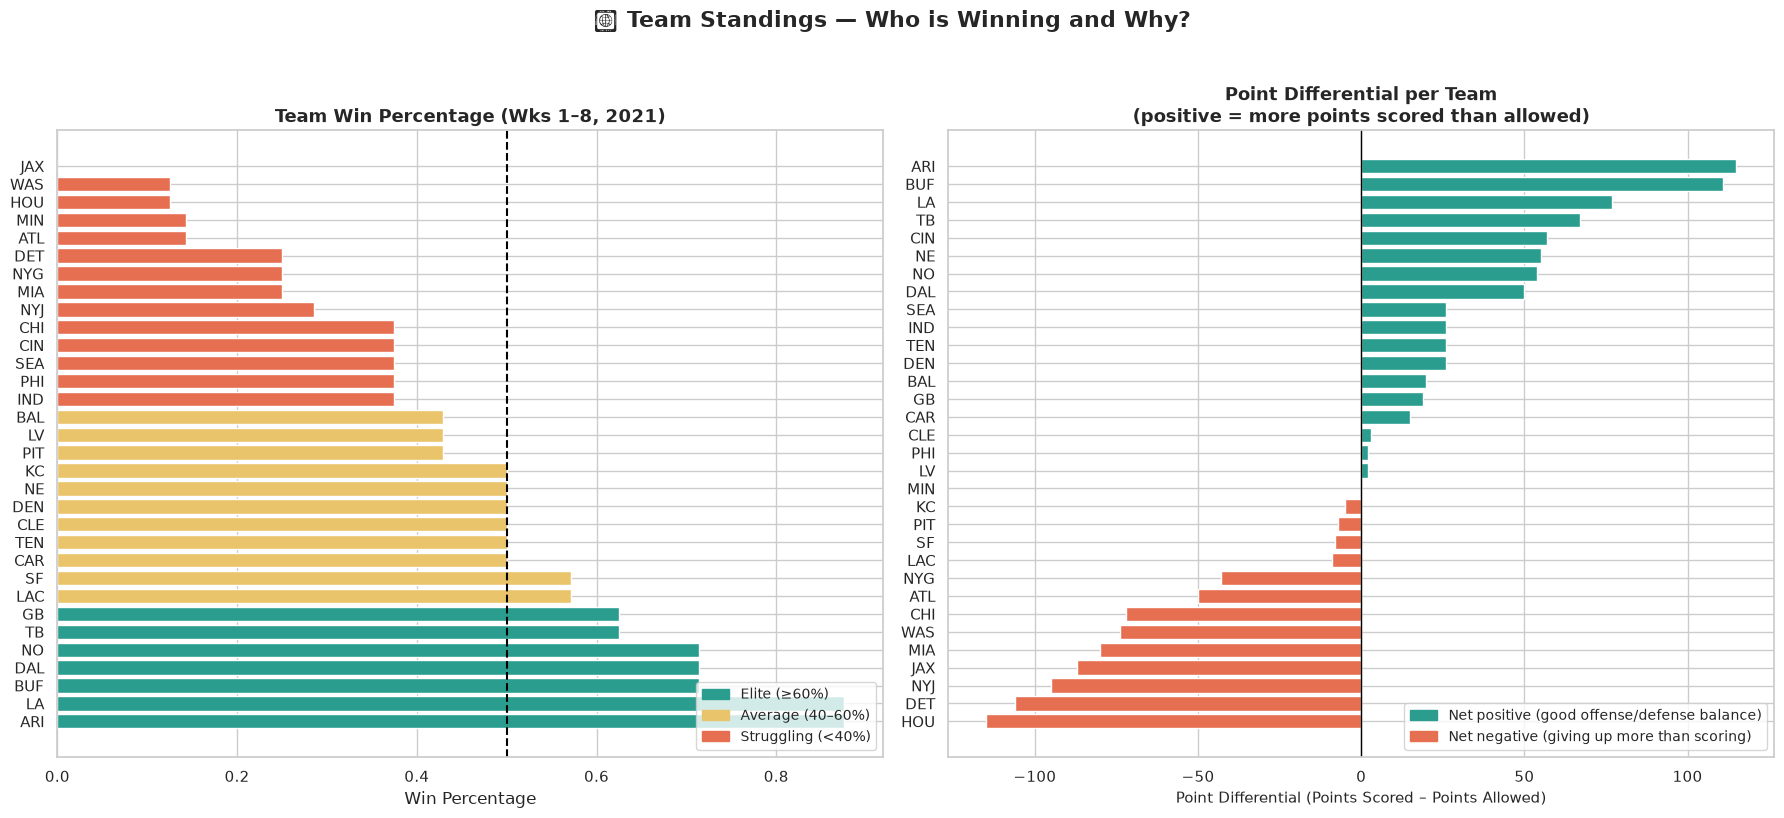

In [2]:
top_standings = standings.sort_values('win_pct', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Win percentage
colors_wins = ['#2a9d8f' if w >= 0.6 else '#e9c46a' if w >= 0.4 else '#e76f51'
               for w in top_standings['win_pct']]
bars = axes[0].barh(top_standings['team'], top_standings['win_pct'],
                    color=colors_wins, edgecolor='white')
axes[0].axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='.500 (50% win rate)')
axes[0].set_xlabel('Win Percentage', fontsize=12)
axes[0].set_title('Team Win Percentage (Wks 1–8, 2021)', fontsize=13, fontweight='bold')
axes[0].legend()
top_patch  = mpatches.Patch(color='#2a9d8f', label='Elite (≥60%)')
mid_patch  = mpatches.Patch(color='#e9c46a', label='Average (40–60%)')
low_patch  = mpatches.Patch(color='#e76f51', label='Struggling (<40%)')
axes[0].legend(handles=[top_patch, mid_patch, low_patch], loc='lower right', fontsize=10)

# Point differential
top_pd = top_standings.sort_values('point_diff', ascending=True)
bar_colors_pd = ['#2a9d8f' if d > 0 else '#e76f51' for d in top_pd['point_diff']]
axes[1].barh(top_pd['team'], top_pd['point_diff'], color=bar_colors_pd, edgecolor='white')
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_xlabel('Point Differential (Points Scored – Points Allowed)', fontsize=11)
axes[1].set_title('Point Differential per Team\n(positive = more points scored than allowed)', 
                  fontsize=13, fontweight='bold')
pos_patch = mpatches.Patch(color='#2a9d8f', label='Net positive (good offense/defense balance)')
neg_patch = mpatches.Patch(color='#e76f51', label='Net negative (giving up more than scoring)')
axes[1].legend(handles=[pos_patch, neg_patch], loc='lower right', fontsize=10)

plt.suptitle('🏆 Team Standings — Who is Winning and Why?', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 2 — Offensive Efficiency: Yards per Play

> **NFL Basics:** Yards per play (YPP) is one of the best indicators of offensive efficiency. A team that consistently gains 6+ yards per play is very hard to stop. It's better than total yards because it accounts for the number of plays run.

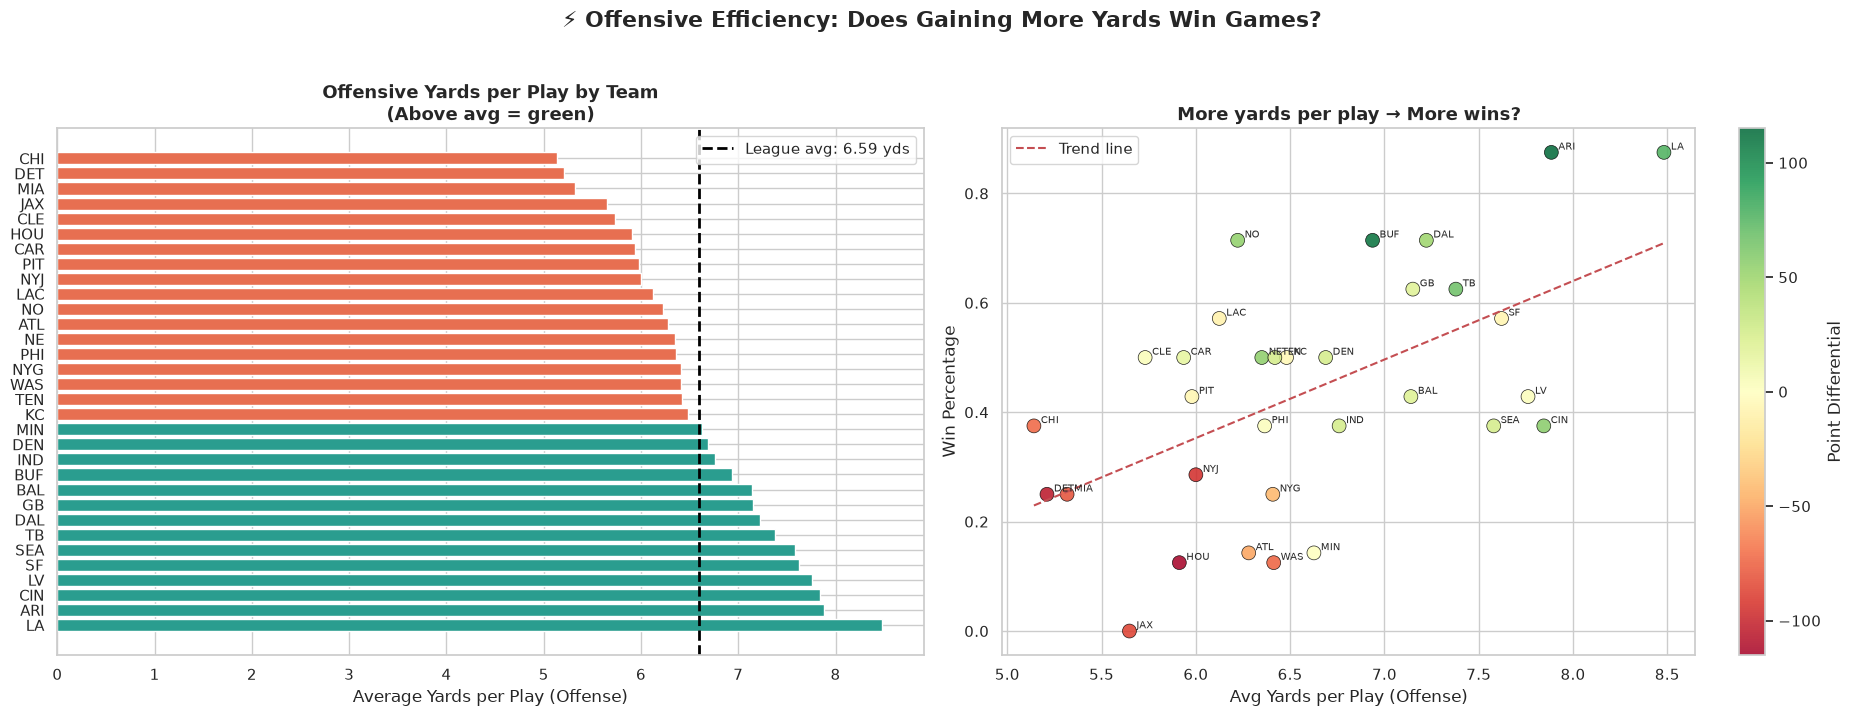

Correlation between offensive yards/play and win rate: 0.553
(1.0 = perfect correlation, 0 = no relationship)


In [3]:
# Offensive efficiency per team
off_stats = plays.groupby('possessionTeam').agg(
    total_yards=('playResult', 'sum'),
    total_plays=('playResult', 'count'),
    avg_yards_per_play=('playResult', 'mean'),
    first_down_rate=('playResult', lambda x: (x >= plays.loc[x.index, 'yardsToGo']).mean())
).reset_index()

# Defensive efficiency: yards allowed per play
def_stats = plays.groupby('defensiveTeam').agg(
    avg_yards_allowed=('playResult', 'mean')
).reset_index().rename(columns={'defensiveTeam': 'team'})

off_stats = off_stats.merge(
    standings[['team', 'win_pct', 'point_diff']],
    left_on='possessionTeam', right_on='team', how='left'
)

off_sorted = off_stats.sort_values('avg_yards_per_play', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(19, 7))

# Offensive YPP
league_avg_off = off_stats['avg_yards_per_play'].mean()
bar_colors_ypp = ['#2a9d8f' if y > league_avg_off else '#e76f51' for y in off_sorted['avg_yards_per_play']]
axes[0].barh(off_sorted['possessionTeam'], off_sorted['avg_yards_per_play'],
             color=bar_colors_ypp, edgecolor='white')
axes[0].axvline(league_avg_off, color='black', linestyle='--', linewidth=2,
                label=f'League avg: {league_avg_off:.2f} yds')
axes[0].set_xlabel('Average Yards per Play (Offense)', fontsize=12)
axes[0].set_title('Offensive Yards per Play by Team\n(Above avg = green)', fontsize=13, fontweight='bold')
axes[0].legend()

# Offensive YPP vs Win Rate scatter
scatter = axes[1].scatter(off_stats['avg_yards_per_play'], off_stats['win_pct'],
                          c=off_stats['point_diff'], cmap='RdYlGn', s=100,
                          edgecolors='black', linewidth=0.5, alpha=0.85)
plt.colorbar(scatter, ax=axes[1], label='Point Differential')
for _, row in off_stats.iterrows():
    axes[1].annotate(row['possessionTeam'],
                     (row['avg_yards_per_play'], row['win_pct']),
                     textcoords='offset points', xytext=(5, 2), fontsize=7)
# Trend line
valid = off_stats.dropna(subset=['win_pct'])
z = np.polyfit(valid['avg_yards_per_play'], valid['win_pct'], 1)
p = np.poly1d(z)
x_line = np.linspace(valid['avg_yards_per_play'].min(), valid['avg_yards_per_play'].max(), 100)
axes[1].plot(x_line, p(x_line), 'r--', linewidth=1.5, label='Trend line')
axes[1].set_xlabel('Avg Yards per Play (Offense)', fontsize=12)
axes[1].set_ylabel('Win Percentage', fontsize=12)
axes[1].set_title('More yards per play → More wins?', fontsize=13, fontweight='bold')
axes[1].legend()

plt.suptitle('⚡ Offensive Efficiency: Does Gaining More Yards Win Games?', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

corr = valid[['avg_yards_per_play', 'win_pct']].corr().iloc[0, 1]
print(f'Correlation between offensive yards/play and win rate: {corr:.3f}')
print(f'(1.0 = perfect correlation, 0 = no relationship)')

---
## 3 — Defensive Pressure: Sacks, Hurries, and Hits

> **NFL Basics:** A great defense doesn't just stop plays — it **disrupts the QB before the pass**:
> - **Sack**: Tackle the QB behind the line for a big loss
> - **Hurry**: Force the QB to throw early or off-balance
> - **Hit**: Hit the QB as he throws, affecting accuracy
>
> Teams with high pressure rates are elite at pass defense.

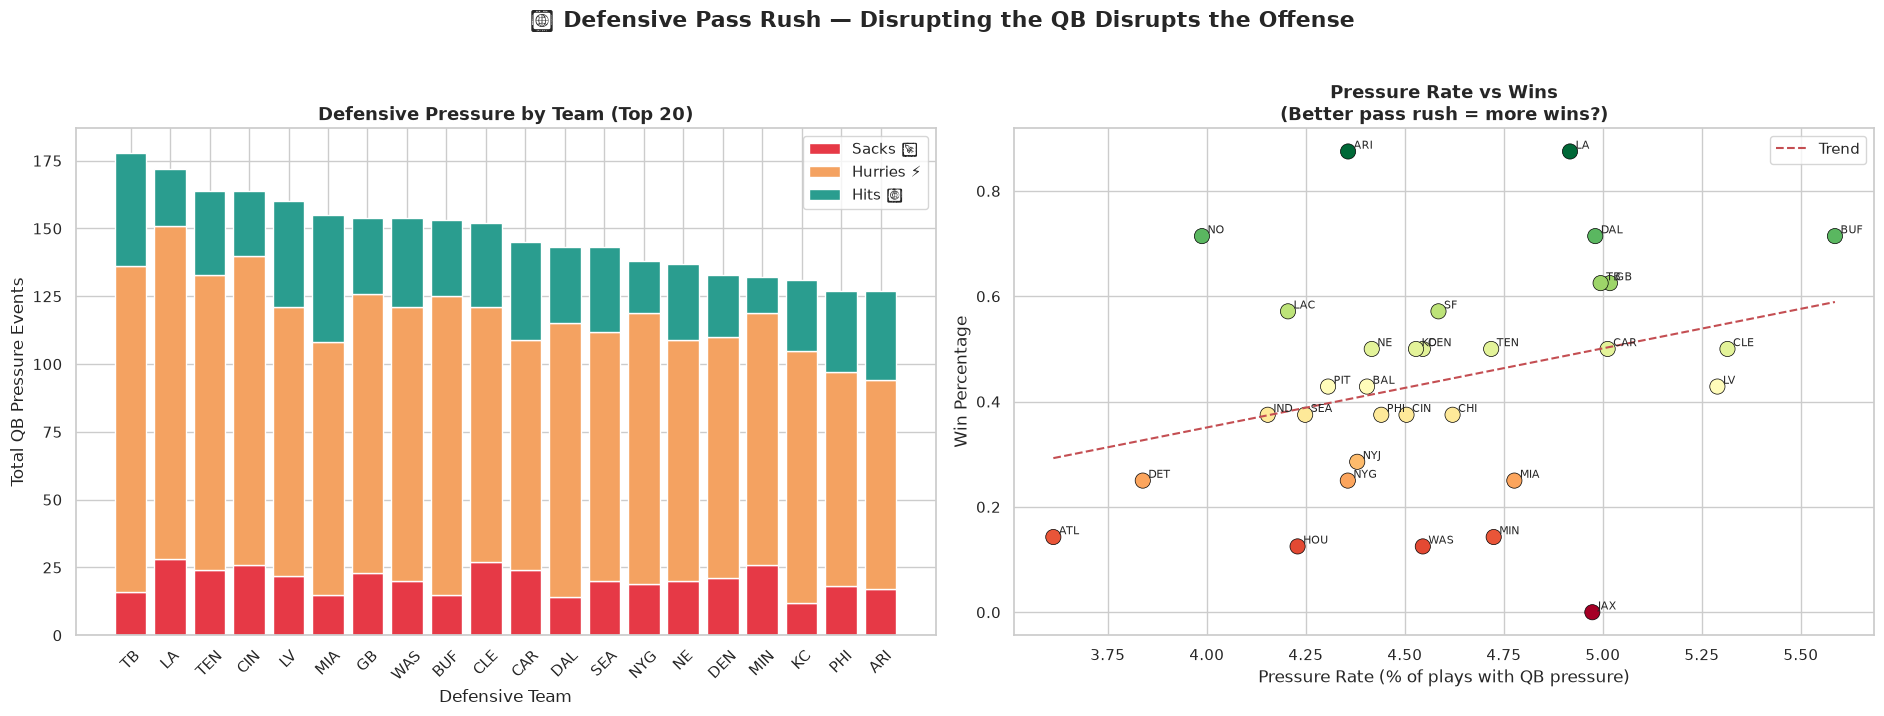

In [4]:
# Defensive players only
defense_pff = pff[pff['pff_role'].isin(['Pass Rush', 'Coverage'])].copy()
defense_pff = defense_pff.merge(plays[['gameId', 'playId', 'defensiveTeam']], on=['gameId', 'playId'], how='left')

# Aggregate pressure per team
pressure = defense_pff.groupby('defensiveTeam').agg(
    sacks=('pff_sack', 'sum'),
    hurries=('pff_hurry', 'sum'),
    hits=('pff_hit', 'sum'),
    plays=('playId', 'count')
).reset_index().dropna(subset=['defensiveTeam'])

pressure['total_pressure'] = pressure['sacks'] + pressure['hurries'] + pressure['hits']
pressure['pressure_rate'] = pressure['total_pressure'] / pressure['plays'] * 100
pressure = pressure.merge(standings[['team', 'win_pct']], left_on='defensiveTeam', right_on='team', how='left')
pressure_sorted = pressure.sort_values('total_pressure', ascending=False).head(20)

fig, axes = plt.subplots(1, 2, figsize=(19, 7))

# Stacked bar: sacks, hurries, hits
x = pressure_sorted['defensiveTeam']
axes[0].bar(x, pressure_sorted['sacks'],   label='Sacks 🛑',   color='#e63946')
axes[0].bar(x, pressure_sorted['hurries'], label='Hurries ⚡',  color='#f4a261',
            bottom=pressure_sorted['sacks'])
axes[0].bar(x, pressure_sorted['hits'],    label='Hits 💥',    color='#2a9d8f',
            bottom=pressure_sorted['sacks'] + pressure_sorted['hurries'])
axes[0].set_xlabel('Defensive Team')
axes[0].set_ylabel('Total QB Pressure Events')
axes[0].set_title('Defensive Pressure by Team (Top 20)', fontsize=13, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()

# Pressure rate vs wins
p_valid = pressure.dropna(subset=['win_pct'])
scatter2 = axes[1].scatter(p_valid['pressure_rate'], p_valid['win_pct'],
                           c=p_valid['win_pct'], cmap='RdYlGn', s=120,
                           edgecolors='black', linewidth=0.5)
for _, row in p_valid.iterrows():
    axes[1].annotate(row['defensiveTeam'],
                     (row['pressure_rate'], row['win_pct']),
                     textcoords='offset points', xytext=(4, 2), fontsize=8)
z2 = np.polyfit(p_valid['pressure_rate'], p_valid['win_pct'], 1)
p2 = np.poly1d(z2)
x_line2 = np.linspace(p_valid['pressure_rate'].min(), p_valid['pressure_rate'].max(), 100)
axes[1].plot(x_line2, p2(x_line2), 'r--', linewidth=1.5, label='Trend')
axes[1].set_xlabel('Pressure Rate (% of plays with QB pressure)', fontsize=12)
axes[1].set_ylabel('Win Percentage', fontsize=12)
axes[1].set_title('Pressure Rate vs Wins\n(Better pass rush = more wins?)', fontsize=13, fontweight='bold')
axes[1].legend()

plt.suptitle('🔥 Defensive Pass Rush — Disrupting the QB Disrupts the Offense', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 4 — QB Performance: Who's the Best Quarterback?

> **NFL Basics:** The quarterback (QB) is the most important player on the field. Key metrics:
> - **Completion rate**: % of passes that are caught (60%+ is good, 70%+ is elite)
> - **Yards per attempt**: How many yards per throw attempt
> - **Interception rate**: How often throws get intercepted (lower = better)

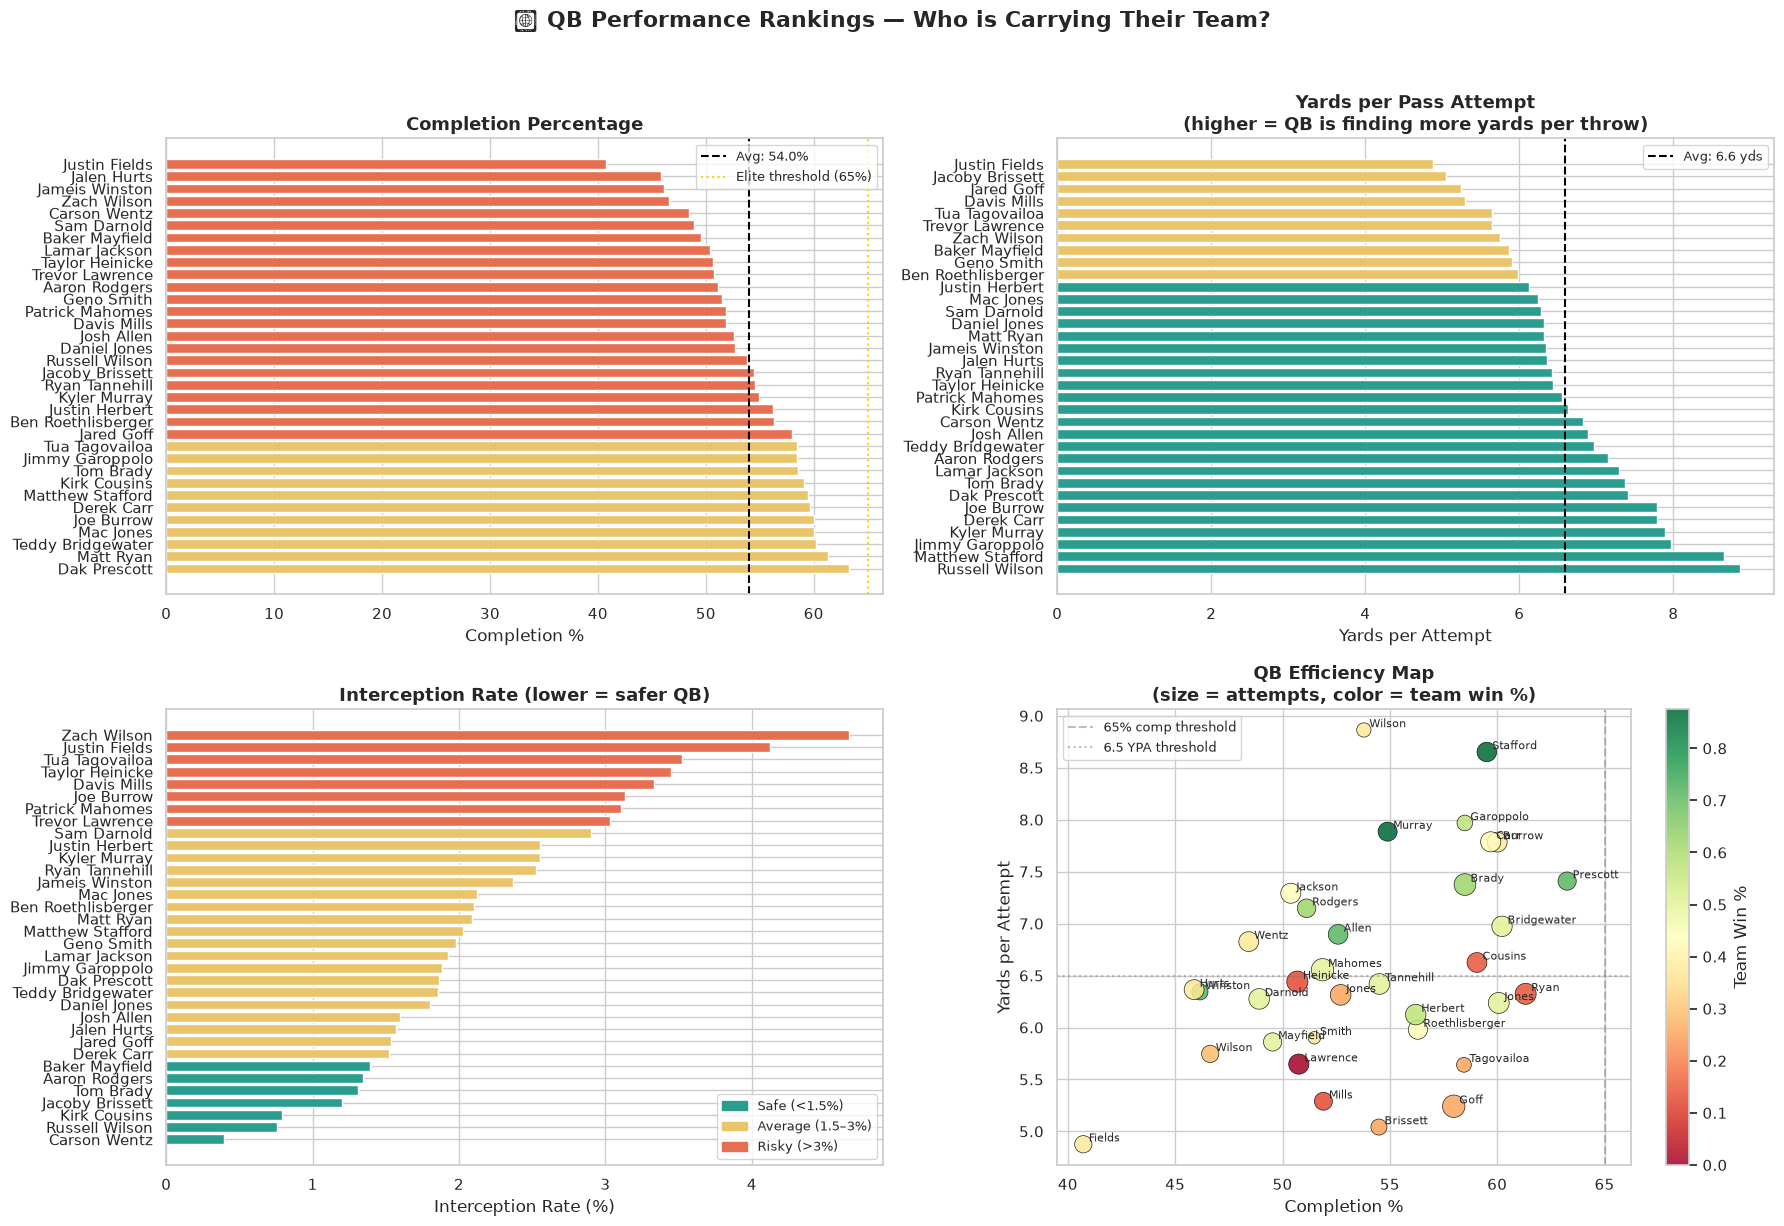

In [5]:
# Get QB plays from PFF
qb_pff = pff[pff['pff_role'] == 'Pass'].merge(
    players[['nflId', 'displayName', 'officialPosition']], on='nflId', how='left'
).merge(
    plays[['gameId', 'playId', 'passResult', 'playResult', 'possessionTeam']], on=['gameId', 'playId'], how='left'
)

qb_stats = qb_pff.groupby(['nflId', 'displayName', 'possessionTeam']).agg(
    attempts=('passResult', 'count'),
    completions=('passResult', lambda x: (x == 'C').sum()),
    interceptions=('passResult', lambda x: (x == 'IN').sum()),
    sacks_taken=('passResult', lambda x: (x == 'S').sum()),
    total_yards=('playResult', 'sum'),
).reset_index()

qb_stats = qb_stats[qb_stats['attempts'] >= 80]  # Min 80 attempts for reliability
qb_stats['completion_pct'] = qb_stats['completions'] / qb_stats['attempts'] * 100
qb_stats['yards_per_attempt'] = qb_stats['total_yards'] / qb_stats['attempts']
qb_stats['int_rate'] = qb_stats['interceptions'] / qb_stats['attempts'] * 100
qb_stats['sack_rate'] = qb_stats['sacks_taken'] / qb_stats['attempts'] * 100
qb_stats = qb_stats.merge(standings[['team', 'win_pct']], left_on='possessionTeam', right_on='team', how='left')
qb_stats = qb_stats.sort_values('completion_pct', ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Completion pct
league_comp = qb_stats['completion_pct'].mean()
colors_comp = ['#2a9d8f' if c >= 65 else '#e9c46a' if c >= 58 else '#e76f51'
               for c in qb_stats['completion_pct']]
bars = axes[0, 0].barh(qb_stats['displayName'], qb_stats['completion_pct'],
                       color=colors_comp, edgecolor='white')
axes[0, 0].axvline(league_comp, color='black', linestyle='--',
                   label=f'Avg: {league_comp:.1f}%')
axes[0, 0].axvline(65, color='gold', linestyle=':', label='Elite threshold (65%)')
axes[0, 0].set_xlabel('Completion %')
axes[0, 0].set_title('Completion Percentage', fontsize=13, fontweight='bold')
axes[0, 0].legend(fontsize=9)

# Yards per attempt
qb_sorted_ypa = qb_stats.sort_values('yards_per_attempt', ascending=False)
colors_ypa = ['#2a9d8f' if y >= 6 else '#e9c46a' if y >= 4.5 else '#e76f51'
              for y in qb_sorted_ypa['yards_per_attempt']]
axes[0, 1].barh(qb_sorted_ypa['displayName'], qb_sorted_ypa['yards_per_attempt'],
                color=colors_ypa, edgecolor='white')
axes[0, 1].axvline(qb_stats['yards_per_attempt'].mean(), color='black', linestyle='--',
                   label=f"Avg: {qb_stats['yards_per_attempt'].mean():.1f} yds")
axes[0, 1].set_xlabel('Yards per Attempt')
axes[0, 1].set_title('Yards per Pass Attempt\n(higher = QB is finding more yards per throw)', 
                     fontsize=13, fontweight='bold')
axes[0, 1].legend(fontsize=9)

# Int rate
qb_sorted_int = qb_stats.sort_values('int_rate', ascending=True)
colors_int = ['#2a9d8f' if r < 1.5 else '#e9c46a' if r < 3 else '#e76f51'
              for r in qb_sorted_int['int_rate']]
axes[1, 0].barh(qb_sorted_int['displayName'], qb_sorted_int['int_rate'],
                color=colors_int, edgecolor='white')
axes[1, 0].set_xlabel('Interception Rate (%)')
axes[1, 0].set_title('Interception Rate (lower = safer QB)', fontsize=13, fontweight='bold')
safe   = mpatches.Patch(color='#2a9d8f', label='Safe (<1.5%)')
avg_p  = mpatches.Patch(color='#e9c46a', label='Average (1.5–3%)')
risky  = mpatches.Patch(color='#e76f51', label='Risky (>3%)')
axes[1, 0].legend(handles=[safe, avg_p, risky], fontsize=9)

# Bubble: comp% vs YPA, sized by attempts
scatter3 = axes[1, 1].scatter(
    qb_stats['completion_pct'], qb_stats['yards_per_attempt'],
    s=qb_stats['attempts'] * 0.8,
    c=qb_stats['win_pct'], cmap='RdYlGn', alpha=0.85,
    edgecolors='black', linewidth=0.5
)
plt.colorbar(scatter3, ax=axes[1, 1], label='Team Win %')
for _, row in qb_stats.iterrows():
    name_short = row['displayName'].split('.')[-1].strip() if '.' in row['displayName'] else row['displayName'].split()[-1]
    axes[1, 1].annotate(name_short,
                        (row['completion_pct'], row['yards_per_attempt']),
                        textcoords='offset points', xytext=(4, 2), fontsize=8)
axes[1, 1].axvline(65, color='gray', linestyle='--', alpha=0.5, label='65% comp threshold')
axes[1, 1].axhline(6.5, color='gray', linestyle=':', alpha=0.5, label='6.5 YPA threshold')
axes[1, 1].set_xlabel('Completion %', fontsize=12)
axes[1, 1].set_ylabel('Yards per Attempt', fontsize=12)
axes[1, 1].set_title('QB Efficiency Map\n(size = attempts, color = team win %)', fontsize=13, fontweight='bold')
axes[1, 1].legend(fontsize=9)

plt.suptitle('🎯 QB Performance Rankings — Who is Carrying Their Team?', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 5 — Head-to-Head Team Report Card

Let's build a **radar chart** comparing two teams across multiple dimensions. Pick any two teams from the dataset.

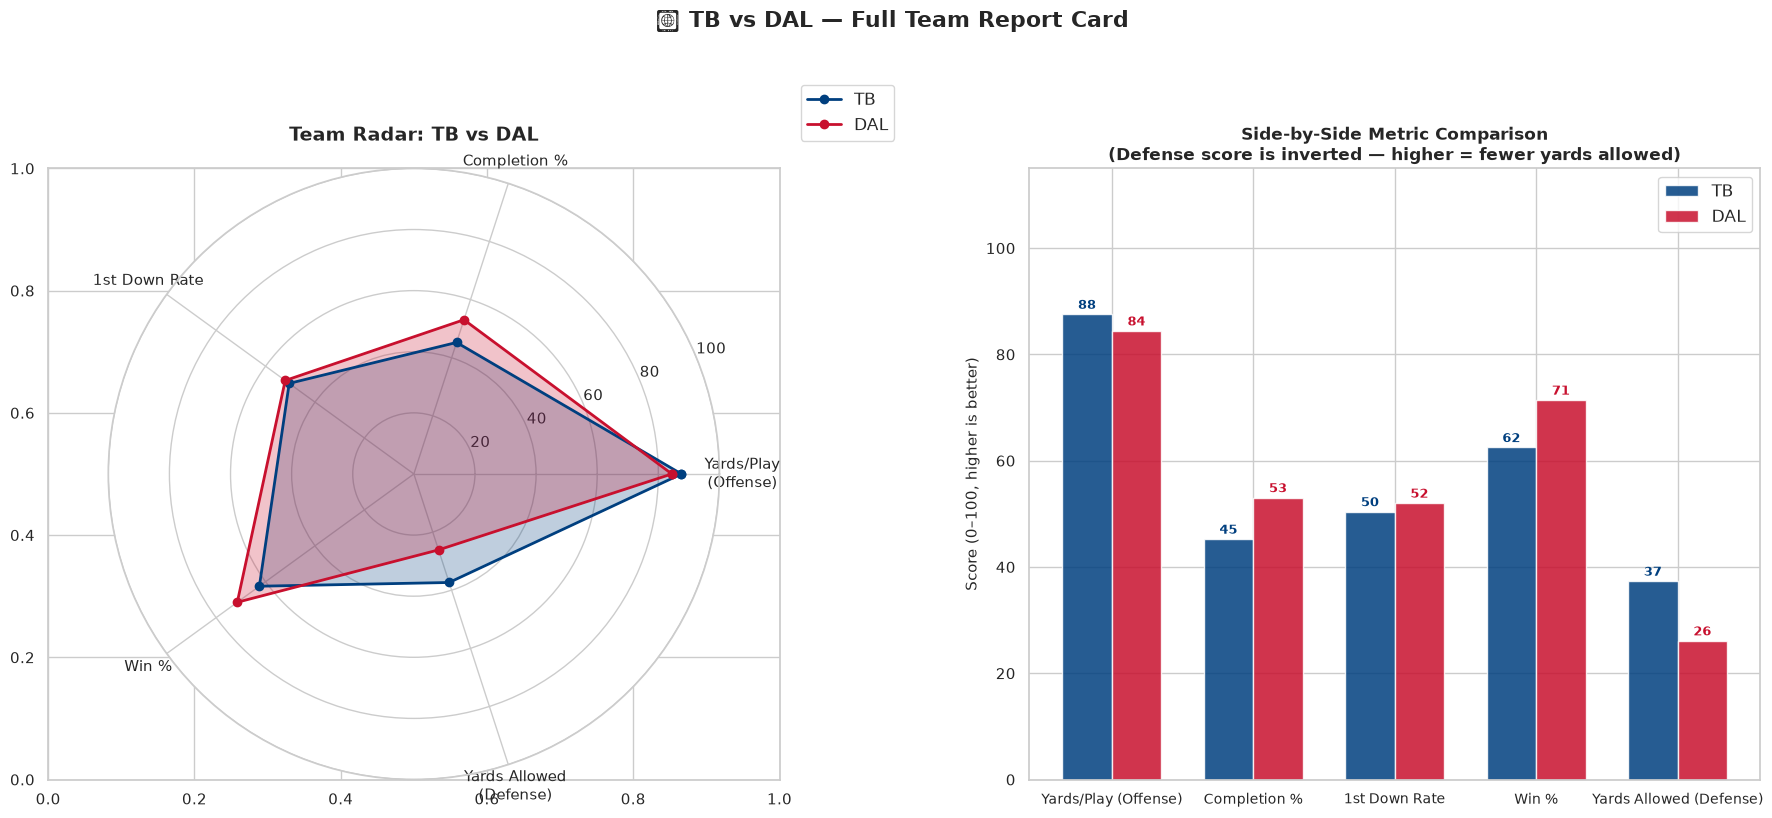


TB Raw Stats:
  Yards/Play (Offense): 7.38
  Completion %: 58.58
  1st Down Rate: 40.13
  Win %: 62.50
  Yards Allowed (Defense): 6.13

DAL Raw Stats:
  Yards/Play (Offense): 7.22
  Completion %: 60.92
  1st Down Rate: 40.61
  Win %: 71.43
  Yards Allowed (Defense): 6.69


In [6]:
# ----- CHANGE THESE TO COMPARE ANY TWO TEAMS -----
TEAM_A = 'TB'   # Tampa Bay Buccaneers
TEAM_B = 'DAL'  # Dallas Cowboys
# --------------------------------------------------

def get_team_metrics(team):
    off  = plays[plays['possessionTeam'] == team]
    deff = plays[plays['defensiveTeam']  == team]
    pp   = off[off['passResult'].notna()]

    metrics = {
        'Yards/Play (Off)': off['playResult'].mean(),
        'Completion %':     (pp['passResult'] == 'C').mean() * 100 if len(pp) > 0 else 0,
        '1st Down Rate':    (off['playResult'] >= off['yardsToGo']).mean() * 100,
        'Win %':            standings.loc[standings['team'] == team, 'win_pct'].values[0] * 100
                            if team in standings['team'].values else 50,
        'Yards Allowed/Play': deff['playResult'].mean(),  # Lower = better defense
    }
    return metrics

metrics_a = get_team_metrics(TEAM_A)
metrics_b = get_team_metrics(TEAM_B)

# Normalize each metric to 0-100 for radar
def normalize(val, lo, hi, invert=False):
    n = (val - lo) / (hi - lo) * 100
    return 100 - n if invert else n

# (metric_name, lo, hi, invert)
metric_config = [
    ('Yards/Play\n(Offense)',    3, 8,   False),
    ('Completion %',            45, 75,  False),
    ('1st Down Rate',           25, 55,  False),
    ('Win %',                    0, 100, False),
    ('Yards Allowed\n(Defense)', 3, 8,  True),   # inverted: fewer yards allowed is better
]

raw_a = [metrics_a['Yards/Play (Off)'], metrics_a['Completion %'], metrics_a['1st Down Rate'],
         metrics_a['Win %'], metrics_a['Yards Allowed/Play']]
raw_b = [metrics_b['Yards/Play (Off)'], metrics_b['Completion %'], metrics_b['1st Down Rate'],
         metrics_b['Win %'], metrics_b['Yards Allowed/Play']]

scores_a = [normalize(v, lo, hi, inv) for v, (_, lo, hi, inv) in zip(raw_a, metric_config)]
scores_b = [normalize(v, lo, hi, inv) for v, (_, lo, hi, inv) in zip(raw_b, metric_config)]
scores_a = [max(0, min(100, s)) for s in scores_a]
scores_b = [max(0, min(100, s)) for s in scores_b]

labels   = [m[0] for m in metric_config]
N        = len(labels)
angles   = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles  += angles[:1]
scores_a += scores_a[:1]
scores_b += scores_b[:1]

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Radar chart
ax_radar = fig.add_subplot(121, polar=True)
ax_radar.plot(angles, scores_a, 'o-', linewidth=2, color='#003f7f', label=TEAM_A)
ax_radar.fill(angles, scores_a, alpha=0.25, color='#003f7f')
ax_radar.plot(angles, scores_b, 'o-', linewidth=2, color='#c8102e', label=TEAM_B)
ax_radar.fill(angles, scores_b, alpha=0.25, color='#c8102e')
ax_radar.set_xticks(angles[:-1])
ax_radar.set_xticklabels(labels, fontsize=11)
ax_radar.set_ylim(0, 100)
ax_radar.set_title(f'Team Radar: {TEAM_A} vs {TEAM_B}', fontsize=14, fontweight='bold', pad=20)
ax_radar.legend(loc='upper right', bbox_to_anchor=(1.3, 1.15), fontsize=12)

# Side-by-side bar comparison
ax2 = axes[1]
x = np.arange(len(metric_config))
width = 0.35
raw_labels_clean = [m[0].replace('\n', ' ') for m in metric_config]
bars1 = ax2.bar(x - width/2, scores_a[:-1], width, label=TEAM_A, color='#003f7f', alpha=0.85)
bars2 = ax2.bar(x + width/2, scores_b[:-1], width, label=TEAM_B, color='#c8102e', alpha=0.85)
ax2.set_xticks(x)
ax2.set_xticklabels(raw_labels_clean, fontsize=10)
ax2.set_ylabel('Score (0–100, higher is better)', fontsize=11)
ax2.set_title(f'Side-by-Side Metric Comparison\n(Defense score is inverted — higher = fewer yards allowed)',
              fontsize=12, fontweight='bold')
ax2.legend(fontsize=12)
ax2.set_ylim(0, 115)
for bar in bars1:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{bar.get_height():.0f}', ha='center', fontsize=9, fontweight='bold', color='#003f7f')
for bar in bars2:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{bar.get_height():.0f}', ha='center', fontsize=9, fontweight='bold', color='#c8102e')

plt.suptitle(f'📊 {TEAM_A} vs {TEAM_B} — Full Team Report Card', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'\n{TEAM_A} Raw Stats:')
for (name, _, _, _), val in zip(metric_config, raw_a):
    print(f'  {name.replace(chr(10), " ")}: {val:.2f}')
print(f'\n{TEAM_B} Raw Stats:')
for (name, _, _, _), val in zip(metric_config, raw_b):
    print(f'  {name.replace(chr(10), " ")}: {val:.2f}')

---
## 6 — What Actually Wins Games? A Multi-Factor Analysis

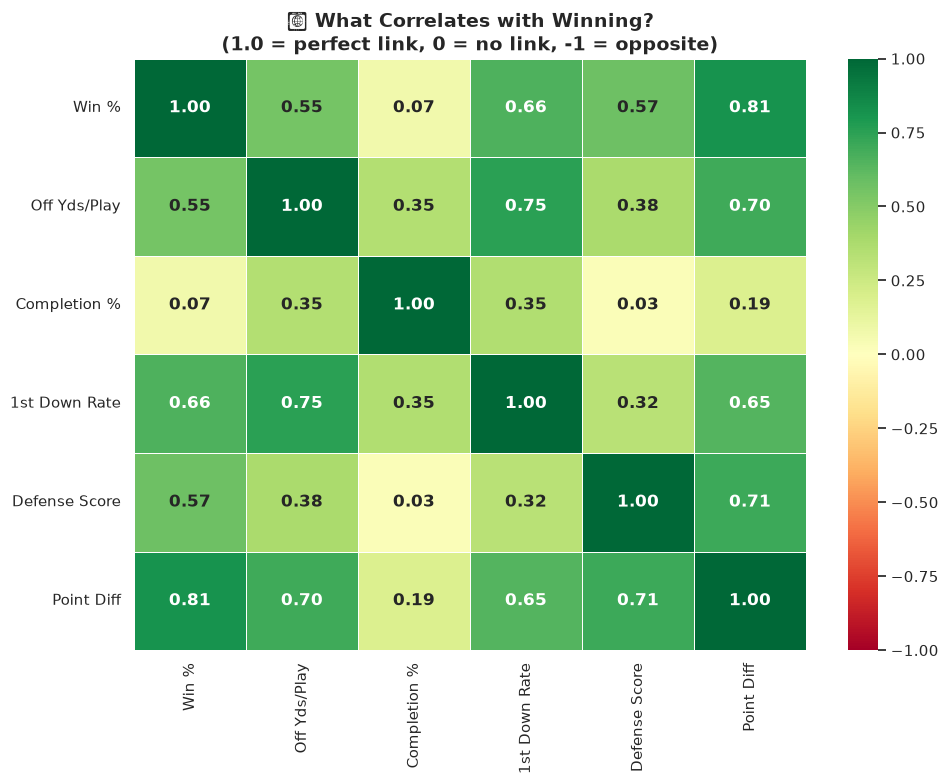

Correlation with Win %:
  Point Diff          : +0.815  ↑ helps  |████████████████|
  1st Down Rate       : +0.661  ↑ helps  |█████████████|
  Defense Score       : +0.572  ↑ helps  |███████████|
  Off Yds/Play        : +0.553  ↑ helps  |███████████|
  Completion %        : +0.073  ↑ helps  |█|


In [7]:
# Build a full team summary table
off_summary = plays.groupby('possessionTeam').agg(
    ypp_off=('playResult', 'mean'),
    first_down_rate=('playResult', lambda x: (x >= plays.loc[x.index, 'yardsToGo']).mean() * 100),
).reset_index().rename(columns={'possessionTeam': 'team'})

def_summary = plays.groupby('defensiveTeam').agg(
    ypp_def=('playResult', 'mean'),
).reset_index().rename(columns={'defensiveTeam': 'team'})

pass_plays = plays[plays['passResult'].notna()]
comp_summary = pass_plays.groupby('possessionTeam').apply(
    lambda x: (x['passResult'] == 'C').mean() * 100
).reset_index()
comp_summary.columns = ['team', 'comp_pct']

full = standings.merge(off_summary, on='team').merge(def_summary, on='team').merge(comp_summary, on='team')
full['defense_score'] = -full['ypp_def']  # Negative: allowing fewer yards is good

# Heatmap of correlations
corr_cols = ['win_pct', 'ypp_off', 'comp_pct', 'first_down_rate', 'defense_score', 'point_diff']
corr_labels = ['Win %', 'Off Yds/Play', 'Completion %', '1st Down Rate', 'Defense Score', 'Point Diff']
corr_matrix = full[corr_cols].corr()
corr_matrix.index   = corr_labels
corr_matrix.columns = corr_labels

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, vmin=-1, vmax=1, ax=ax, linewidths=0.5,
            annot_kws={'size': 12, 'weight': 'bold'})
ax.set_title('🔗 What Correlates with Winning?\n(1.0 = perfect link, 0 = no link, -1 = opposite)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Correlation with Win %:')
correlations = full[corr_cols].corr()['win_pct'].drop('win_pct').sort_values(ascending=False)
for metric, val in correlations.items():
    label = corr_labels[corr_cols.index(metric)]
    bar = '█' * int(abs(val) * 20)
    direction = '↑ helps' if val > 0 else '↓ hurts'
    print(f'  {label:20s}: {val:+.3f}  {direction}  |{bar}|')

---
## Final Summary

| Factor | Impact on Winning | Why it Matters |
|---|---|---|
| **Point Differential** | Very High | Teams that consistently outscores win consistently |
| **Offensive Yards/Play** | High | Efficient offense sustains drives and scores |
| **1st Down Rate** | High | Moving the chains keeps offense on the field |
| **Completion %** | Moderate | Accurate QBs make better decisions |
| **Defensive Pressure** | Moderate | Disrupting the QB disrupts the whole offense |

### Key takeaway for new NFL viewers

> **A team wins by being more efficient, not just having more talent.** The best teams:
> 1. Move the ball consistently on offense (high yards/play)
> 2. Make smart decisions (high completion %, low turnovers)
> 3. Pressure and disrupt the opponent's QB
> 4. Convert 3rd downs to keep drives alive

When you watch a game, look for **who wins the 3rd down battle** — that team almost always wins the game.